# Data on the Line · Çözüm Notebook'u

*Turning Demand Insights into Balanced Production* · Nimbus Dynamics vakası · KoçDigital, Boğaziçi
Üniversitesi Data & AI Summit

Oturumda çalıştığınız vakanın çözümü. Adım başlıkları kendi notebook'unuzdakilerle aynı.

## Genel bakış

Vakadaki soru: “Mevcut hat Ocak–Mart 2026 talebini karşılayabilir mi, karşılayamıyorsa ne
yapmalıyız?” Cevap için talebi tahmin ettik, konsensüs talebi üretim planına ve takt süresine
çevirdik, hattı en sıkışık aya göre bir MILP ile dengeledik ve ACİL siparişi hattın gerçek
temposuyla değerlendirdik.

Sonuç: bugünkü düzen şubatı kaldırmıyor, ama işler yeniden dağıtılınca yine 7 istasyonla bütün
kurallara uyan bir hat kurulabiliyor. ACİL sipariş için ek istasyon yerine ocakta 551 adet önden
üretim öneriyoruz.

## Başlarken

İlk iki hücre kütüphaneleri yükler, yardımcı fonksiyonları tanımlar ve hat dengeleme problemi için
solver'ı seçer.

In [1]:
# HAZIR · Başlangıç: kütüphaneler ve veri

import importlib
import json
import math
import os
import re
import shutil
import subprocess
import sys
import zipfile
import zlib
from datetime import datetime
from importlib.metadata import PackageNotFoundError, version
from importlib.util import find_spec
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Colab'de veri dosyaları GitHub'dan otomatik iner; kendi bilgisayarınızda bu adım atlanır
REPO_URL = "https://github.com/burcu-koca-kd/data-on-the-line.git"
CONTENT = Path("/content")
REPO = CONTENT / "data-on-the-line"
CASE_DIR = REPO / "tr/2_Vaka"


def _clone():
    try:
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(REPO)],
                       check=True, capture_output=True)
    except subprocess.CalledProcessError:
        print("✗ Veri dosyaları GitHub'dan indirilemedi. İnternet bağlantınızı kontrol edin, "
              "ardından notebook bağlantısını yeniden açın ya da bu hücreyi tekrar çalıştırın.")
        raise RuntimeError("Veri dosyaları indirilemedi (yukarıdaki mesaja bakın).") from None


def _update():
    """İndirilmiş kopyayı GitHub'daki son sürüme getirir; release/ ve submission/ klasörlerine
    dokunmaz."""
    git = ["git", "-C", str(REPO)]
    fetched = subprocess.run(git + ["fetch", "-q", "--depth", "1"], capture_output=True)
    if fetched.returncode == 0:
        subprocess.run(git + ["reset", "-q", "--hard", "origin/main"], capture_output=True)


def _uploaded_case():
    """Depoda vaka klasörü yoksa Colab'e ya da Drive'a yüklenmiş bir 2_Vaka klasörünü (ya da
    2_Vaka.zip dosyasını) arar."""
    for archive in sorted(CONTENT.glob("2_Vaka*.zip")):
        with zipfile.ZipFile(archive) as z:
            z.extractall(CONTENT)
    for root in (CONTENT, CONTENT / "drive" / "MyDrive"):
        for folder in (root / "2_Vaka", *root.glob("*/2_Vaka"), root):
            if (folder / "data" / "tasks.csv").exists():
                return folder
    return None


if "google.colab" in sys.modules:
    # daha önce indirilmiş bir kopya varsa en son sürüme getirilir (internet yoksa sessizce
    # geçilir)
    if REPO.exists():
        _update()
    # eski kopyada vaka klasörü yoksa depo baştan indirilir
    if not CASE_DIR.exists():
        shutil.rmtree(REPO, ignore_errors=True)
        _clone()
    # vaka klasörü depoda henüz yoksa: yüklenmiş bir kopya aranır
    if not CASE_DIR.exists():
        CASE_DIR = _uploaded_case()
        if CASE_DIR is None:
            print("✗ Vaka dosyaları henüz yayımlanmamış görünüyor: depoda 2_Vaka klasörü yok. "
                  "Eğitmeninize haber verin. Eğitmeniniz 2_Vaka klasörünü dağıttıysa: (1) "
                  "2_Vaka.zip dosyasını Colab'in sol kenarındaki Dosyalar paneline sürükleyin ya "
                  "da (2) 2_Vaka klasörünü Drive'ınıza koyup Dosyalar panelinden Drive'ı "
                  "bağlayın; sonra bu hücreyi yeniden çalıştırın.")
            raise RuntimeError("Vaka klasörü bulunamadı (yukarıdaki mesaja bakın).")
        print(f"Depoda vaka klasörü yok; yüklenen kopya kullanılıyor: {CASE_DIR}")
    os.chdir(CASE_DIR)

CASE_FILES = Path(".")
if not Path("data").exists() and (Path("../2_Vaka") / "data").exists():
    # notebook 3_Çözüm klasöründen açıldıysa veri ve şifreli dosyalar yandaki 2_Vaka'dan
    # okunur
    CASE_FILES = Path("../2_Vaka")


def _install(*packages):
    result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(f"pip install {' '.join(packages)} başarısız oldu. Hata mesajının sonu:")
        print(result.stderr[-1500:])


def _pulp_major():
    try:
        return int(version("pulp").split(".")[0])
    except PackageNotFoundError:
        return 0


def _forget_pulp():
    """PuLP'u bellekten siler; bir sonraki import yeni kurulan paketleri görür."""
    for name in [m for m in sys.modules if m == "pulp" or m.startswith("pulp.")]:
        del sys.modules[name]
    importlib.invalidate_caches()


# Colab'de PuLP ya kurulu değildir ya da 4. sürümü kuruludur; vaka 3. sürümle yazıldı
if not 2 <= _pulp_major() < 4:
    _install("pulp>=2.7,<4")
    _forget_pulp()
if _pulp_major() >= 4:
    print("⚠ PuLP 3 kurulamadı, hâlâ 4. sürüm yüklü. Çekirdeği yeniden başlatıp (Çalışma zamanı → "
          "Oturumu yeniden başlat) bu hücreyi tekrar çalıştırın.")
import pulp

DATA, RELEASE = CASE_FILES / "data", Path("release")


PRODUCTS = ["ND100", "ND200", "ND300"]
MONTHS = ["2026-01", "2026-02", "2026-03"]

history = pd.read_csv(DATA / "demand_history.csv").fillna({"Calendar_Note": ""})
plan_q1 = pd.read_csv(DATA / "promo_price_plan.csv", dtype={"Promo_Status": str})
plan_q1 = plan_q1.fillna({"Calendar_Note": "", "Promo_Status": ""})
calendar = pd.read_csv(DATA / "production_calendar.csv")
products = pd.read_csv(DATA / "products.csv")
tasks = pd.read_csv(DATA / "tasks.csv")
precedence = pd.read_csv(DATA / "precedence.csv")
current = pd.read_csv(DATA / "current_line.csv")

TASKS = list(tasks.Task)
# TIME[iş][ürün]: saniye cinsinden süre
TIME = {r.Task: {p: getattr(r, f"{p}_sec") for p in PRODUCTS} for r in tasks.itertuples()}
GROUP = dict(zip(tasks.Task, tasks.Process_Group))                 # her işin süreç grubu
# (a, b): a'nın istasyonu b'ninkinden sonra gelemez (aynı istasyon olabilir)
ARCS = list(zip(precedence.Predecessor, precedence.Successor))
CURRENT_LINE = dict(zip(current.Task, current.Station))            # bugünkü hat {iş: istasyon}

# kontrol hücrelerinin kullandığı doğru değerler: ocak ve kıyas yöntemi
NAIVE_WAPE, NAIVE_BIAS = 0.1070, -0.0864
JAN_AVAILABLE, JAN_PLANNED, JAN_TAKT = 1039500, 11180, 92.98


def fmt(x, decimals=0):
    """Sayıyı Türkçe biçimde yazar: 1.039.500 ya da 92,98."""
    text = f"{x:,.{decimals}f}"
    return text.replace(",", " ").replace(".", ",").replace(" ", ".")


def pct(x, decimals=1, signed=False):
    """Oranı yüzde olarak yazar: %10,7; signed=True ile +%10,7 ya da −%8,6."""
    sign = ("+" if x >= 0 else "−") if signed else ("−" if x < 0 else "")
    return f"{sign}%{fmt(abs(x) * 100, decimals)}"


def show(table, decimals=2):
    """Tabloyu Türkçe sayı biçimiyle gösterir: 1.039.500 ve 92,98 (tam sayılar ondalıksız)."""
    whole = [c for c in table.select_dtypes("float") if (table[c].dropna() % 1 == 0).all()]
    try:
        styled = table.style.format(precision=decimals, decimal=",", thousands=".")
        display(styled.format(precision=0, decimal=",", thousands=".", subset=whole))
    except (ImportError, AttributeError):          # biçimli tablolar için jinja2 gerekir
        display(table)


def _as_dict(values):
    """Sözlüğü ya da pandas Series'i düz bir sözlüğe çevirir; None ise None kalır."""
    return None if values is None else dict(values)


def add_features(df):
    """Modellerin sık kullandığı sütunları ekler. Hem history hem plan_q1 için çalışır."""
    out = df.copy()
    period = pd.PeriodIndex(out.Month, freq="M")
    out["t"] = period.astype("int64")                              # ay sayacı, eğilim için
    out["month"] = period.month                                    # ayın numarası (1–12)
    price = out["Avg_Price_EUR"] if "Avg_Price_EUR" in out else out["Planned_Price_EUR"]
    # log(fiyat / liste fiyatı); 0 indirim olmadığını gösterir
    out["discount"] = np.log(price / out["List_Price_EUR"])
    past = history.set_index(["Product", "Month"]).Demand_Units
    a_year_earlier = [str(pd.Period(m, freq="M") - 12) for m in out.Month]
    # aynı ürünün on iki ay önceki talebi
    out["lag12"] = [past.get(key) for key in zip(out.Product, a_year_earlier)]
    return out


history, plan_q1 = add_features(history), add_features(plan_q1)

In [2]:
# HAZIR · Çözücü: önce CBC denenir, açılmazsa HiGHS kullanılır

def _solver_works(solver):
    try:
        test = pulp.LpProblem("test", pulp.LpMinimize)
        x = pulp.LpVariable("x", cat="Binary")
        test += x
        test += x >= 1
        test.solve(solver)
        return pulp.LpStatus[test.status] == "Optimal"
    except Exception:
        return False


def _pick_solver():
    global pulp
    # gapRel=0 (CBC ve HiGHS): çözücü en iyi çözümü kanıtlayana kadar çalışır; varsayılan ayarla
    #   %0,01 farkla durabilir, bu modelde bu fark yarım saniyelik dengeyi gizleyebilir
    options = {"msg": False, "timeLimit": 60, "gapRel": 0}
    if _solver_works(pulp.PULP_CBC_CMD(msg=False)):
        return pulp.PULP_CBC_CMD(**options), "CBC"
    # yedek çözücü: yalnızca CBC açılmazsa (örneğin bazı Mac'lerde) kurulur
    if find_spec("highspy") is None:
        _install("highspy")
        _forget_pulp()
        import pulp
    if hasattr(pulp, "HiGHS") and _solver_works(pulp.HiGHS(msg=False)):
        # HiGHS'te ön çözümleme (presolve) kapalı: açıkken bu modelde en dengeli hattı zaman zaman
        #   kaçırıyor
        return pulp.HiGHS(**options, presolve="off"), "HiGHS"
    return None, None


SOLVER, SOLVER_NAME = _pick_solver()

if SOLVER:
    print(f"Veri yüklendi ✓ | çözücü: {SOLVER_NAME}")
else:
    print("Veri yüklendi, ama çözücü başlatılamadı. En kolay çözüm notebook'u Colab'de açmak. "
          "Kendi Mac'inizde çalışmak istiyorsanız Terminal'de 'pip install highspy' komutunu "
          "çalıştırıp çekirdeği yeniden başlatın.")

Veri yüklendi ✓ | çözücü: HiGHS


Talep geçmişi (son satırlar):


,Month,Product,Product_Name,Demand_Units,Promo,Avg_Price_EUR,List_Price_EUR,Working_Days,Calendar_Note,t,month,discount,lag12
174,2025-11,ND100,Standard,4.320,0,"109,420","110,380",20,,670,11,"-0,009",4.449
175,2025-11,ND200,Plus,3.586,0,"142,800","143,500",20,,670,11,"-0,005",3.273
176,2025-11,ND300,Pro,2.623,0,"186,250","187,650",20,,670,11,"-0,007",2.638
177,2025-12,ND100,Standard,5.240,0,"110,250","110,380",23,,671,12,"-0,001",4.857
178,2025-12,ND200,Plus,3.976,0,"142,320","143,500",23,,671,12,"-0,008",3.533
179,2025-12,ND300,Pro,3.838,1,"158,050","187,650",23,,671,12,"-0,172",2.761


Ocak–Mart 2026 planı:


,Month,Product,Product_Name,Promo,Promo_Status,Planned_Price_EUR,List_Price_EUR,Working_Days,Calendar_Note,t,month,discount,lag12
0,2026-01,ND100,Standard,0,,"112,570","113,140",21,,672,1,"-0,005",5.094
1,2026-01,ND200,Plus,0,,"146,340","147,080",21,,672,1,"-0,005",3.633
2,2026-01,ND300,Pro,1,approved,"176,070","192,340",21,,672,1,"-0,088",2.541
3,2026-02,ND100,Standard,0,,"112,570","113,140",20,,673,2,"-0,005",4.558
4,2026-02,ND200,Plus,0,,"146,340","147,080",20,,673,2,"-0,005",3.124
5,2026-02,ND300,Pro,0,,"191,380","192,340",20,,673,2,"-0,005",2.372
6,2026-03,ND100,Standard,1,pending,"101,320","113,140",21,Ramazan Bayramı,674,3,"-0,110",4.150
7,2026-03,ND200,Plus,0,,"146,340","147,080",21,Ramazan Bayramı,674,3,"-0,005",3.050
8,2026-03,ND300,Pro,0,,"191,380","192,340",21,Ramazan Bayramı,674,3,"-0,005",2.383


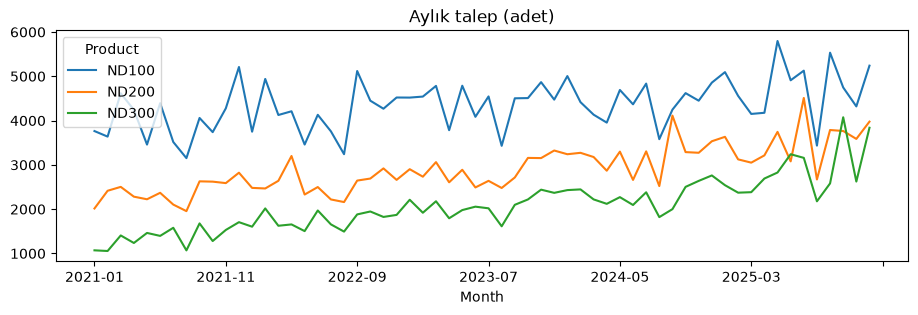

In [3]:
print("Talep geçmişi (son satırlar):")
show(history.tail(6), decimals=3)
print("Ocak–Mart 2026 planı:")
show(plan_q1, decimals=3)
demand = history.pivot(index="Month", columns="Product", values="Demand_Units")
demand.plot(figsize=(11, 3), title="Aylık talep (adet)")
plt.show()

Kerem'in planında iki satır önemli: ocakta Pro promosyonu `approved`, martta Standard promosyonu
`pending`. Grafikte büyüme, her yıl benzer dönemlerde iniş çıkışlar ve promosyon aylarında
sıçramalar görülüyor; modelin bunları açıklaması gerekiyor.

## 1 · Talep tahmini

Soru: 31 Aralık itibarıyla Ocak–Mart talebini ürün bazında tahmin etmek ve tahmine neden
güvenilebileceğini göstermek. Ece'nin koyduğu sınır belirleyici: “Tahmini bugün, yani 31 Aralık 2025
itibarıyla elimizde olan bilgilerle yapacağız.”

Modeli iki ölçütle değerlendirdik:

$$\text{WAPE}=\frac{\sum|\text{gerçekleşen}-\text{tahmin}|}{\sum \text{gerçekleşen}},\qquad \text{Bias}=\frac{\sum(\text{tahmin}-\text{gerçekleşen})}{\sum \text{gerçekleşen}}$$

WAPE hatanın büyüklüğünü ölçer; fazla ve eksik tahminler birbirini götürmez. Bias işaretlidir:
pozitifse fazla, negatifse eksik tahmin ediyoruz. Planlama için ikisi de önemli; sistematik fazla
tahmin stok, sistematik eksik tahmin kaçan sipariş demek.

In [4]:
# HAZIR · Tahmin araçları

def wape(actual, forecast):
    """WAPE: mutlak hataların toplamının gerçekleşen talep toplamına oranı. Düşük olan daha iyi."""
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return np.abs(actual - forecast).sum() / actual.sum()


def bias(actual, forecast):
    """Bias: (tahmin toplamı − gerçekleşen toplamı) / gerçekleşen toplamı. Pozitifse fazla,
    negatifse eksik tahmin ediyoruz."""
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return (forecast - actual).sum() / actual.sum()


def seasonal_naive(train, test):
    """Kıyas yöntemi: geçen yılın aynı ayının talebi."""
    return test["lag12"].to_numpy(float)


def check_backtest(backtest):
    """Geriye dönük testinizi kıyas yöntemiyle çalıştırır ve doğru sonuçla karşılaştırır."""
    problems = set()

    def probe(train, test):
        if len(train) and train.t.max() >= test.t.min():
            problems.add("future")
        if "Demand_Units" in test.columns:
            problems.add("actuals")
        return seasonal_naive(train, test)

    bt = backtest(probe)
    if len(bt) == 0:
        print("Geriye dönük test henüz bir şey döndürmüyor.")
    elif "future" in problems:
        print("✗ Bazı başlangıç aylarında model, tahmin ettiği aylardan sonraki verileri de "
              "görüyor.")
    elif "actuals" in problems:
        print("✗ test tablosunda hâlâ Demand_Units sütunu var, yani model gerçekleşen talebi "
              "görebiliyor. Modeli çağırmadan önce bu sütunu çıkarın: "
              "test.drop(columns='Demand_Units').")
    else:
        w, b = wape(bt.Demand_Units, bt.Forecast), bias(bt.Demand_Units, bt.Forecast)
        if len(bt) == 72 and abs(w - NAIVE_WAPE) < 0.0005 and abs(b - NAIVE_BIAS) < 0.0005:
            print(f"✓ Veriyi doğru ayırmışsınız: {len(bt)} tahmin, mevsimsel naif için WAPE "
                  f"{pct(w)}, bias {pct(b, signed=True)}.")
        else:
            print("✗ Doğru kurulmuş bir test, mevsimsel naif yöntem için 72 tahmin, WAPE "
                  f"{pct(NAIVE_WAPE)} ve bias {pct(NAIVE_BIAS, signed=True)} verir. Sizin "
                  f"sonucunuz: {len(bt)} tahmin, WAPE {pct(w)}, bias {pct(b, signed=True)}.")


def compare(models, backtest):
    """Verilen modellerin hepsini geriye dönük testten geçirir; WAPE, bias ve ürün bazında bias'ı
    gösterir."""
    rows = {}
    for name, model in models.items():
        bt = backtest(model)
        if len(bt) == 0:
            print("Geriye dönük test henüz bir şey döndürmüyor.")
            return
        w = wape(bt.Demand_Units, bt.Forecast)
        rows[name] = {"WAPE": pct(w), "Bias": pct(bias(bt.Demand_Units, bt.Forecast), signed=True)}
        for p, g in bt.groupby("Product"):
            rows[name][f"Bias {p}"] = pct(bias(g.Demand_Units, g.Forecast), signed=True)
        if w < 0.01:
            print(f"⚠ {name}: WAPE {pct(w)}. Bu kadar düşük bir hata genellikle modelin "
                  "gerçekleşen değerleri gördüğü anlamına gelir; veri sızıntısı olup olmadığını "
                  "kontrol edin.")
    display(pd.DataFrame.from_dict(rows, orient="index"))


def plot_forecast(history, forecast):
    """Geçmiş talebi ve Ocak–Mart 2026 tahminini ürün bazında aynı grafikte gösterir (tahmin
    kesikli çizgi)."""
    past = history.pivot(index="Month", columns="Product", values="Demand_Units")
    ahead = forecast.pivot(index="Month", columns="Product", values="Forecast_Units")
    ahead = pd.concat([past.tail(1), ahead])         # kesikli çizgi aralık 2025'ten başlasın
    past.index = pd.PeriodIndex(past.index, freq="M")
    ahead.index = pd.PeriodIndex(ahead.index, freq="M")
    ax = past.plot(figsize=(11, 3.5), title="Aylık talep ve Ocak–Mart 2026 tahmini (adet)")
    colours = [line.get_color() for line in ax.get_lines()]
    ahead.plot(ax=ax, style="--", color=colours, legend=False)
    return ax

### Adım 1.1 · Geriye dönük test

Çalışma esaslarındaki backtest: Aralık 2023–Eylül 2025 arasında üç ayda bir 8 başlangıç ayı; her
birinde model o aya kadarki veriyi (o ay dâhil) görüp sonraki üç ayı tahmin ediyor. 8 × 3 ay × 3
ürün = 72 tahmin.

Ayırmayı zamana göre yaptık, çünkü ölçülen hata modelin gerçekte kullanılacağı koşuldaki hataya
benzemeli. Rastgele ayırmada model geleceği görür ve hata olduğundan küçük çıkar. Aynı nedenle
`test`'ten `Demand_Units`'i çıkardık; iş günü, fiyat ve promosyon geçmişte en az üç ay önceden
kesinleştiği için modele açık.

In [5]:
# çalışma esaslarındaki 8 başlangıç ayı
ORIGINS = ["2023-12", "2024-03", "2024-06", "2024-09", "2024-12", "2025-03", "2025-06", "2025-09"]


def backtest(model):
    """Geriye dönük test. Her tahmin için bir satır döndürür: Month, Product, Demand_Units ve
    Forecast."""
    results = []
    for origin in ORIGINS:
        # başlangıç ayının sıra numarası
        last = pd.Period(origin, freq="M").ordinal
        # başlangıç ayı dâhil, o aya kadar olan her şey
        train = history[history.t <= last]
        # sonraki üç ay, daha ötesi değil
        test = history[(history.t > last) & (history.t <= last + 3)]
        # model gerçekleşen değerleri görmüyor
        forecast = model(train, test.drop(columns="Demand_Units"))
        rows = test[["Month", "Product", "Demand_Units"]]
        results.append(rows.assign(Forecast=np.asarray(forecast, float), Origin=origin))
    if not results:
        return pd.DataFrame(columns=["Month", "Product", "Demand_Units", "Forecast"])
    return pd.concat(results)

In [6]:
check_backtest(backtest)

✓ Veriyi doğru ayırmışsınız: 72 tahmin, mevsimsel naif için WAPE %10,7, bias −%8,6.


72 tahmin; mevsimsel naif benchmark için WAPE %10,7, bias −%8,6. Bias negatif, çünkü geçen yılın
aynı ayını tekrarlamak büyüyen talebi hep bir yıl geriden izliyor. Her model bu iki sayıyı geçmeli.

### Adım 1.2 · Kendi modelimiz

Talebi üç şeyin belirlediğini düşündük. Eğilim: veri salonları açıldıkça üç ürün de büyüyor. İş
günü: bayramlar yıldan yıla ay değiştiriyor (Ramazan Bayramı 2021'de mayıstaydı, 2026'da martta),
yani takvim ayı çalışılan gün sayısını söylemiyor. Fiyat: promosyonlar %5 ile %15 arasında; `Promo`
göstergesi derinliği bilmiyor, fiyatın liste fiyatına oranı biliyor.

Her ürün için log-doğrusal bir regresyon kurduk:

$$\log(\text{talep}) = a + b\,t + \beta\,\log(\text{iş günü}) + \varepsilon\,\log\frac{\text{fiyat}}{\text{liste fiyatı}}$$

Etkiler çarpımsal, β ve ε doğrudan esneklik. Geri dönüşte `exp(ŷ + σ²/2)` kullandık; `exp(ŷ)`
ortalamayı değil medyanı verir. Pencere olarak 60 ayın tamamını ve son 36 ayı denedik; karşılaştırma
için Holt-Winters ile ay kuklalı bir regresyon ekledik.

In [7]:
def log_regression(train, test, features, window=None):
    """log(talep) için regresyon; ürün başına en küçük kareler yöntemiyle.
    features(df) açıklayıcı sütunları döndürür; window: kullanılacak son eğitim ayı sayısı (None
    ise bütün geçmiş)."""
    out = pd.Series(index=test.index, dtype=float)
    for p in PRODUCTS:
        tr, te = train[train.Product == p], test[test.Product == p]
        if window:
            tr = tr[tr.t > tr.t.max() - window]
        y = np.log(tr.Demand_Units)
        coef, *_ = np.linalg.lstsq(features(tr), y, rcond=None)
        residual_var = np.var(y - features(tr) @ coef)
        # logaritmadan geri dönüş, lognormal ortalama düzeltmesiyle
        out[te.index] = np.exp(features(te) @ coef + residual_var / 2)
    return out.to_numpy()


def drivers(df):
    """log(talep) = a + b·t + β·log(iş günü) + ε·indirim (indirim = log(fiyat / liste fiyatı)):
    ürün başına dört katsayı."""
    return np.column_stack([np.ones(len(df)), df.t, np.log(df.Working_Days), df.discount])


def my_model(train, test):
    """Referans model: son 36 ayla kurulan açıklayıcı değişkenli regresyon."""
    return log_regression(train, test, drivers, window=36)

Karşılaştırma modelleri: Holt-Winters, ay kuklaları ve promosyon göstergesiyle regresyon, açıklayıcı
değişkenli regresyonun 60 aylık hâli.

In [8]:
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing


def holt_winters(train, test):
    """Holt-Winters: toplamsal eğilim, çarpımsal on iki aylık mevsimsellik. Yalnızca talep serisini
    kullanır."""
    out = pd.Series(index=test.index, dtype=float)
    for p in PRODUCTS:
        tr, te = train[train.Product == p].sort_values("t"), test[test.Product == p]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            series = tr.Demand_Units.to_numpy(float)
            model = ExponentialSmoothing(series, trend="add", seasonal="mul", seasonal_periods=12)
            fit = model.fit()
        ahead = fit.forecast(int(te.t.max() - tr.t.max()))
        out[te.index] = [ahead[int(t - tr.t.max() - 1)] for t in te.t]
    return out.to_numpy()


def month_dummies(df):
    """log(talep) = a + b·t + c·promosyon göstergesi + 11 ay kuklası: ürün başına 14 katsayı."""
    dummies = [(df.month == m).astype(float) for m in range(2, 13)]
    return np.column_stack([np.ones(len(df)), df.t, df.Promo] + dummies)


def with_month_dummies(train, test):
    return log_regression(train, test, month_dummies)


def drivers_all_history(train, test):
    return log_regression(train, test, drivers)

In [9]:
compare({"Mevsimsel naif": seasonal_naive,
         "Holt-Winters": holt_winters,
         "Ay kuklaları + promosyon göstergesi": with_month_dummies,
         "Açıklayıcı değişkenler, bütün geçmiş": drivers_all_history,
         "Benim modelim": my_model}, backtest)

,WAPE,Bias,Bias ND100,Bias ND200,Bias ND300
Mevsimsel naif,"%10,7","−%8,6","−%3,9","−%9,9","−%15,5"
Holt-Winters,"%9,4","−%1,3","+%0,0","−%2,6","−%2,1"
Ay kuklaları + promosyon göstergesi,"%9,2","+%2,3","+%1,3","+%0,4","+%6,3"
"Açıklayıcı değişkenler, bütün geçmiş","%5,2","+%2,2","+%1,1","−%0,3","+%7,6"
Benim modelim,"%5,1","+%1,1","+%0,7","+%0,7","+%2,3"


Holt-Winters (%9,4) ve ay kuklalı regresyon (%9,2) benchmark'ı az farkla geçiyor; ikisi de ayın kaç
iş günü olduğunu ve indirimin derinliğini bilmiyor. Açıklayıcı değişkenlerle hata %5 dolayına
iniyor. Yani grafikteki mevsimsellik görüntüsünün büyük kısmı takvimden ve promosyonlardan geliyor.

Ürün bazında bias kararı verdi. 60 aylık model toplamda iyi (%5,2), ama Pro'yu +%7,6 fazla tahmin
ediyor: Pro'nun büyümesi yavaşlıyor ve beş yıla oturtulan sabit büyüme oranı ilk yılların hızını
geleceğe taşıyor. 36 aylık model aynı toplam hatayla (%5,1) Pro bias'ını +%2,3'e indiriyor. Referans
model bu.

Bir sınırlılık: pencereyi aynı backtest'e bakarak seçtik, dolayısıyla %5,1 biraz iyimser (seçim
yanlılığı).

Sık hatalar: model içinde `train` yerine `history` kullanmak, log modeli `exp` ile geri çevirmemek,
yalnızca toplam WAPE'ye bakıp Pro'daki sapmayı kaçırmak. Ağaç modelleri eğilimi eğitim verisinin
dışına taşıyamadığı için büyüyen seride eksik tahmin ediyor; eğilim önce çıkarılırsa kılavuzdaki
denemelerde %8 dolayına iniyor.

### Adım 1.3 · Ocak–Mart 2026 tahmini

2026 değerleri Kerem'in planında, ama planda bir tuzak var: “Ocaktaki Pro promosyonu onaylandı.
Standard'ın mart promosyonu ise hâlâ onay bekliyor; plana şimdilik işledim, onaylanırsa mart güçlü
geçer.”

31 Aralıkta mart promosyonu kesin değil. Onu temel tahmine koymak sonucu biliyormuş gibi davranmak
olur; modele gelecekten veri girmediği için bu bir veri sızıntısı değil, kesinleşmemiş bilgiyi kesin
saymak. Temel tahmini promosyonsuz kurup promosyonu ayrı bir senaryo olarak gösterdik. Onaylı ocak
promosyonu kalıyor.

Modelimiz `Promo`'ya değil indirime baktığı için `Promo = 0` yetmez; fiyatı da promosyonsuz plan
fiyatına (112,57 €) döndürüp `add_features` ile `discount`'u yeniden hesapladık.

In [10]:
future = plan_q1.copy()
# 31 Aralıkta hâlâ onay bekleyen promosyon kesin değil, temel tahmine girmiyor
late = future.Promo_Status == "pending"
regular = future[future.Promo == 0].groupby("Product").Planned_Price_EUR.first()
future.loc[late, "Planned_Price_EUR"] = future.loc[late, "Product"].map(regular)
future.loc[late, "Promo"] = 0
future = add_features(future)          # discount fiyattan yeniden hesaplanıyor

forecast = future.assign(Forecast_Units=my_model(history, future))
shown = ["Month", "Product", "Promo", "Planned_Price_EUR", "Forecast_Units"]
show(forecast[shown].round({"Forecast_Units": 0}))

,Month,Product,Promo,Planned_Price_EUR,Forecast_Units
0,2026-01,ND100,0,"112,57",4.678
1,2026-01,ND200,0,"146,34",3.680
2,2026-01,ND300,1,"176,07",3.228
3,2026-02,ND100,0,"112,57",4.454
4,2026-02,ND200,0,"146,34",3.544
5,2026-02,ND300,0,"191,38",2.765
6,2026-03,ND100,0,"112,57",4.693
7,2026-03,ND200,0,"146,34",3.737
8,2026-03,ND300,0,"191,38",2.918


In [11]:
# karşılaştırma için: Kerem'in planını olduğu gibi kullansaydık
as_planned = plan_q1.assign(Forecast_Units=my_model(history, plan_q1))
march = (forecast.Month == "2026-03") & (forecast.Product == "ND100")
base = forecast.loc[march, "Forecast_Units"].item()
promo = as_planned.loc[march, "Forecast_Units"].item()
print(f"Mart ND100 | temel tahmin (promosyonsuz): {fmt(base)} | onay bekleyen promosyonla: "
      f"{fmt(promo)} | fark: {fmt(promo - base)} adet")

Mart ND100 | temel tahmin (promosyonsuz): 4.693 | onay bekleyen promosyonla: 5.547 | fark: 854 adet


Mart Standard için temel tahmin 4.693 adet; planı olduğu gibi kullansaydık 5.547 olacaktı. 854
adetlik fark temel tahminin yaklaşık %18'i. Pro'nun ocak tahmininin yüksek olması onaylı
promosyondan.

Geçmiş talep ve tahmin (kesikli çizgi).

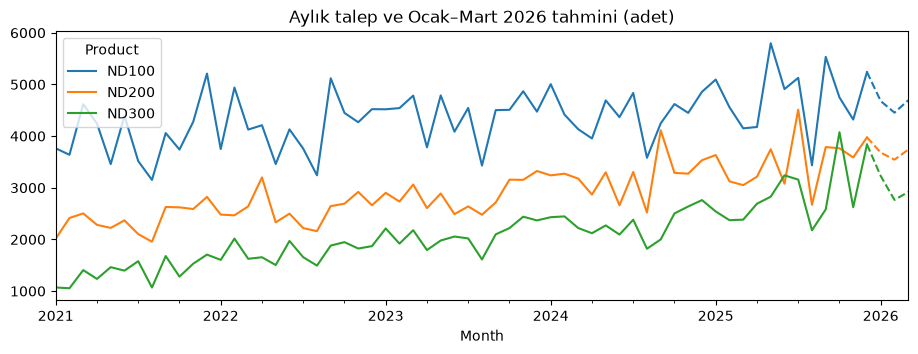

In [12]:
plot_forecast(history, forecast)
plt.show()

## 2 · Üretim planı ve takt süresi

45. dakikada Deniz'in konsensüs planı geldi; bundan sonra herkes aynı talepten çalıştı. Deniz'in
soruları: “Hattı en çok hangi ay zorluyor? Kaç istasyona ihtiyacımız var? Mevcut düzen bunu kaldırır
mı?” İlki bu bölümde, diğerleri Bölüm 3'te.

In [13]:
# HAZIR · Plan araçları

def unlock_release(file, password):
    """Şifreli dosyayı notebook'un yanındaki release/ klasörüne açar."""
    if not password:
        print("Salonda duyurulan şifreyi yazın ve hücreyi yeniden çalıştırın.")
        return
    # büyük harf ya da boşlukla yazılsa da çalışır
    password = "-".join(password.lower().split())
    with zipfile.ZipFile(file) as z:
        for member in z.infolist():
            try:
                z.extract(member, ".", pwd=password.encode())
            except RuntimeError:
                print("Şifre yanlış, lütfen tekrar deneyin.")
                return
            except (zipfile.BadZipFile, zlib.error):
                Path(member.filename).unlink(missing_ok=True)       # yarım kalan dosya silinir
                print("Şifre yanlış, lütfen tekrar deneyin.")
                return
        print("Açılan dosyalar:", ", ".join(n for n in z.namelist() if not n.endswith("/")))


def load_consensus():
    """Konsensüs talep planını {(ay, ürün): adet} biçiminde bir sözlük olarak döndürür."""
    if not (RELEASE / "consensus_demand.csv").exists():
        print("Önce 45. dakika dosyasını açın.")
        return {}
    demand = pd.read_csv(RELEASE / "consensus_demand.csv")
    show(demand.pivot(index="Month", columns="Product", values="Consensus_Demand_Units"))
    return {(r.Month, r.Product): r.Consensus_Demand_Units for r in demand.itertuples()}


def add_urgent(D):
    """ACİL siparişi konsensüs talebine (D) ekler ve yeni sözlüğü döndürür."""
    if not D:
        print("Önce 45. dakika dosyasını açın.")
        return {}
    if not (RELEASE / "urgent_order.csv").exists():
        print("Önce 95. dakika dosyasını açın.")
        return dict(D)
    urgent = pd.read_csv(RELEASE / "urgent_order.csv")
    show(urgent)
    out = dict(D)
    for r in urgent.itertuples():
        out[(r.Month, r.Product)] += r.Additional_Units
    return out


def _mark(ok):
    return "✓" if ok else "✗"


INTRO_MIX = [0.4, 0.35, 0.25]                        # girişte önerilen geçici ürün karması


def _intro_mix(mix):
    """Ürün karması hâlâ girişteki geçici değerse True döndürür."""
    return bool(mix) and [mix.get(p) for p in PRODUCTS] == INTRO_MIX


def check_plan(avail, plan, takt=None, design_month=None, C=None, mix=None):
    """Ocak sonuçlarınızı doğru değerlerle karşılaştırır; DESIGN_MONTH, C ve MIX'in birbiriyle
    tutarlı olup olmadığına bakar."""
    avail, takt, mix = _as_dict(avail), _as_dict(takt) or {}, _as_dict(mix)
    if not avail or plan is None or len(plan) == 0:
        print("available_time() ve production_plan() henüz bir sonuç döndürmüyor.")
        return
    jan_planned = plan[plan.Month == "2026-01"].Planned_Production.sum()
    ok = abs(avail.get("2026-01", 0) - JAN_AVAILABLE) < 1
    print(_mark(ok), f"Ocak ayının kullanılabilir süresi (doğru değer: {fmt(JAN_AVAILABLE)} sn)")
    ok = abs(jan_planned - JAN_PLANNED) <= 3
    print(_mark(ok), f"Ocak ayının toplam planlanan üretimi (doğru değer: {fmt(JAN_PLANNED)} adet)")
    if takt:
        ok = abs(takt.get("2026-01", 0) - JAN_TAKT) < 0.03
        print(_mark(ok), f"Ocak ayının takt süresi (doğru değer: {fmt(JAN_TAKT, 2)} sn)")
    if C is not None or mix:
        design_takt = takt.get(design_month)
        ok = (bool(mix) and abs(sum(mix.values()) - 1) < 1e-6
              and C is not None and design_takt is not None and abs(C - design_takt) < 0.01)
        print(_mark(ok), "MIX'teki payların toplamı 1 ve C, DESIGN_MONTH ayının takt süresine "
                         "eşit (bu kontrol hangi ayı seçtiğinize bakmaz)")
    if _intro_mix(mix):
        print("⚠ MIX hâlâ girişte önerilen geçici değer. Bölüm 2'de hesapladığınız ürün karmasını "
              "yazın.")

### Adım 2.1 · Dosyayı açmak

Şifre `navy-crane`. Deniz'in e-postası yöntemi veriyor: ay sonunda sonraki ayın talebinin %10'u
kadar stok, ilk geçişte testi geçemeyenler hurda, ve “takt süresini hurdaya gidecekler dâhil bu
planlanan üretimden hesaplayın.” (Literatürde planlı çevrim süresi.) Planda nisan da var, çünkü mart
sonu stoku nisan talebine bağlı.

In [14]:
unlock_release(CASE_FILES / "release_45_min.zip", password="navy-crane")
D = load_consensus()   # {(ay, ürün): konsensüs talep}

Açılan dosyalar: release/consensus_demand.csv, release/Deniz_Email_45_min.pdf


Product,ND100,ND200,ND300
Month,,,
2026-01,4.759,3.699,3.241
2026-02,4.568,3.568,2.690
2026-03,4.787,3.758,2.833
2026-04,4.802,3.789,2.855


### Adım 2.2 · Kullanılabilir süre ve planlanan üretim

Bir iş günü 2 × (7,5 − 0,5) − 0,25 = 13,75 saat; ocak 21 × 13,75 × 3.600 = 1.039.500 sn.

Şubatta Hasan'ın mesajı devreye giriyor: “Motor şubatta değişecek, hat iki iş günü duracak.”
Takvimde bu `Additional_Stop_Hours` = 27,5 saat. Şubat: (20 × 13,75 − 27,5) × 3.600 = 891.000 sn. Bu
sütunu atlayan takım şubatı rahat gördü; kontrol hücresi yalnızca ocağa baktığı için hatayı
yakalamadı.

Planlanan üretim, ürün ve ay bazında:

$$\text{planlanan üretim} = \frac{\text{talep} + \text{ay sonu stoku} - \text{ay başı stoku}}{\text{ilk geçiş verimi}}$$

Ay başı stoku bir önceki ayın kapanışı, ocak için 31 Aralık stoku; yuvarlama yalnızca en sonda. Ocak
ND100: (4.759 + 0,10 × 4.568 − 780) / 0,985 = 4.503,4 → 4.504. Hurdayı verime bölerek hesaba kattık;
iş sürelerine de eklemek aynı kaybı iki kez saymak olurdu.

In [15]:
def available_time(calendar):
    """Her ayın kullanılabilir süresini saniye cinsinden döndürür: {ay: saniye}."""
    hours_per_shift = calendar.Hours_per_Shift - calendar.Break_Hours_per_Shift
    net_hours = calendar.Shifts_per_Day * hours_per_shift - calendar.Daily_Maintenance_Hours
    seconds = (calendar.Working_Days * net_hours - calendar.Additional_Stop_Hours) * 3600
    return dict(zip(calendar.Month, seconds))


def production_plan(D):
    """Her ay ve ürün için bir satır döndürür: Month, Product ve Planned_Production."""
    stock, rows = products.set_index("Product"), []
    for p in PRODUCTS:
        opening = stock.loc[p, "Inventory_2025_12_31"]
        for k, m in enumerate(MONTHS):
            next_month = (MONTHS + ["2026-04"])[k + 1]
            # ay sonu stoku: sonraki ayın talebinin %10'u
            closing = 0.10 * D[(next_month, p)]
            needed = (D[(m, p)] + closing - opening) / stock.loc[p, "First_Pass_Yield"]
            rows.append(dict(Month=m, Product=p, Planned_Production=math.ceil(needed - 1e-9)))
            # bu ayın kapanış stoku, sonraki ayın açılış stoku olur
            opening = closing
    return pd.DataFrame(rows)


avail, plan = available_time(calendar), production_plan(D)

In [16]:
show(plan.pivot(index="Month", columns="Product", values="Planned_Production"))

Product,ND100,ND200,ND300
Month,,,
2026-01,4.504,3.517,3.159
2026-02,4.660,3.661,2.774
2026-03,4.862,3.838,2.908


Ocakta 11.180 adet üretilecek; talep (11.699) daha yüksek, çünkü yılı fazla stokla kapattık. En çok
üretim martta (11.608). Sık hatalar: her ayın açılışı için 31 Aralık stokunu kullanmak (ocak doğru
çıkar, şubat ve mart yanlış) ve verime bölmek yerine çarpmak.

### Adım 2.3 · Takt süresi ve tasarım ayı

Takt = kullanılabilir süre / planlanan üretim. Hangi ay için tasarlayacağımızı Selin söylüyor:
“Ocak–mart boyunca hat tek bir düzende çalışacak, çeyrek ortasında değiştirmeyeceğiz.” Tek düzen üç
aya da yetmeli, o hâlde belirleyici olan takt süresi en kısa ay; en çok talep ya da üretim olan ay
değil. Karmayı da o ayın planından aldık ve `C`'yi yuvarlamadık.

In [17]:
def units_of(plan, month):
    return plan[plan.Month == month].set_index("Product").Planned_Production


def mix_of(plan, month):
    """Bir ayın planlanan üretimindeki ürün karması {ürün: pay}."""
    units = units_of(plan, month)
    return (units / units.sum()).to_dict()


planned = plan.groupby("Month").Planned_Production.sum()
takt = {m: avail[m] / planned[m] for m in MONTHS}
show(pd.DataFrame({"Planlanan üretim": planned, "Kullanılabilir süre (sn)": pd.Series(avail),
                   "Takt (sn)": pd.Series(takt)}))

# hat üç ay aynı düzende çalışacak: takt süresi en kısa ay belirleyici
DESIGN_MONTH = min(takt, key=takt.get)
C, MIX = takt[DESIGN_MONTH], mix_of(plan, DESIGN_MONTH)
print(f"Tasarım ayı: {DESIGN_MONTH} | C = {fmt(C, 2)} sn | MIX:",
      ", ".join(f"{p} {fmt(v, 3)}" for p, v in MIX.items()))

,Planlanan üretim,Kullanılabilir süre (sn),Takt (sn)
2026-01,11.180,1.039.500,"92,98"
2026-02,11.095,891.000,"80,31"
2026-03,11.608,1.039.500,"89,55"


Tasarım ayı: 2026-02 | C = 80,31 sn | MIX: ND100 0,420, ND200 0,330, ND300 0,250


In [18]:
check_plan(avail, plan, takt, DESIGN_MONTH, C, MIX)

✓ Ocak ayının kullanılabilir süresi (doğru değer: 1.039.500 sn)
✓ Ocak ayının toplam planlanan üretimi (doğru değer: 11.180 adet)
✓ Ocak ayının takt süresi (doğru değer: 92,98 sn)
✓ MIX'teki payların toplamı 1 ve C, DESIGN_MONTH ayının takt süresine eşit (bu kontrol hangi ayı seçtiğinize bakmaz)


Takt: ocak 92,98, şubat 80,31, mart 89,55 sn. Tasarım ayı şubat: 20 iş günü ve iki günlük duruş onu
en sıkışık ay yapıyor. Duruşu atlayan takım 89,23 sn bulur ve 6 istasyonun yettiğini sanırdı. Şubat
karması: 0,42 Standard, 0,33 Plus, 0,25 Pro. Kontrol hücresi hangi ayı seçtiğinize bakmıyor; bu
karar bilerek takımlara bırakılmıştı.

## 3 · Hat dengeleme

Soru: şubat taktında (80,31 sn) çeyrek boyunca çalışacak bir düzen. Selin'in öncelik sırası: “önce
istasyon sayısını en aza indirin. Aynı sayıda istasyonla birden fazla düzen mümkünse en dengelisini
isterim”. Hakem (`check_assignment`) yalnızca temel kurallara bakıyor; yazışmalardaki kurallar ona
yazılmadı.

In [19]:
# HAZIR · Hat araçları

def weighted(mix):
    """Verilen ürün karması {ürün: pay} için ağırlıklı iş sürelerini döndürür."""
    mix = dict(mix)
    return {i: sum(mix[p] * TIME[i][p] for p in PRODUCTS) for i in TASKS}


def station_loads(line, mix):
    """Her istasyonun işleri, ağırlıklı yükü, ürün bazında süresi ve süreç grupları; yuvarlanmamış
    değerlerle."""
    w, out = weighted(mix), {}
    for task, k in sorted(dict(line).items()):
        if task not in TIME:
            continue
        if k not in out:
            out[k] = {"Tasks": [], "Load": 0.0, "Groups": set(), **{p: 0 for p in PRODUCTS}}
        s = out[k]
        s["Tasks"].append(task)
        s["Load"] += w[task]
        s["Groups"].add(GROUP[task])
        for p in PRODUCTS:
            s[p] += TIME[task][p]
    return dict(sorted(out.items()))


def station_table(line, mix):
    """Her istasyon için bir satır: işler, ağırlıklı yük, ürün bazında süre ve süreç grupları
    (yükler gösterim için yuvarlanır)."""
    rows = {k: {"Tasks": ", ".join(s["Tasks"]), "Weighted": round(s["Load"], 2),
                **{p: s[p] for p in PRODUCTS}, "Groups": ", ".join(sorted(s["Groups"]))}
            for k, s in station_loads(line, mix).items()}
    return pd.DataFrame.from_dict(rows, orient="index")


def check_assignment(line, C, mix):
    """Hakem: verilen hatta ({iş: istasyon}) yalnızca temel kuralları denetler: her iş bir
    istasyonda, iş sırası, takt süresi ve istasyon numaraları. Boş liste, bu kurallarda sorun
    olmadığı anlamına gelir; yazışmalardaki kurallara bakmaz."""
    line = dict(line)
    issues = [f"{i} hiçbir istasyona atanmamış." for i in TASKS if i not in line]
    issues += [f"{i} diye bir iş yok." for i in line if i not in TIME]
    issues += [f"İş sırası bozuk: {a} ({line[a]}. istasyon), {b} işinden ({line[b]}. istasyon) "
               "önce gelmeli."
               for a, b in ARCS if a in line and b in line and line[a] > line[b]]
    stations = sorted(set(line.values()))
    if stations != list(range(1, len(stations) + 1)):
        issues.append("İstasyonlar 1'den başlayıp boşluksuz numaralanmalı (şu anki numaralar: "
                      f"{stations}).")
    for k, s in station_loads(line, mix).items():
        if s["Load"] > C + 1e-9:
            issues.append(f"{k}. istasyon: {fmt(s['Load'], 2)} sn > takt {fmt(C, 2)} sn")
    return issues


def capacity(line, mix, seconds):
    """Hattın verilen sürede (saniye) kaç adet üretebileceğini döndürür."""
    loads = station_loads(line, mix)
    if not loads:
        return 0
    busiest = max(s["Load"] for s in loads.values())
    return math.floor(seconds / busiest)


def _own_rules(rules, line, C, mix):
    """Sizin kural fonksiyonunuzu çalıştırır ve sonucu bir liste olarak döndürür."""
    found = rules(line, C, mix)
    if found is None:
        print("Not: check_rules bir liste döndürmedi (None), bu yüzden kurallarınız denetlenmedi. "
              "Fonksiyonun sonunda return problems satırı olmalı.")
    return list(found or [])


def _report(line, C, mix, rules=None):
    issues = check_assignment(line, C, mix)
    print("Hakem (temel kurallar):" + ("" if issues else " sorun yok"))
    for issue in issues:
        print("  -", issue)
    if rules is None:
        print("Hakem yazışmalardaki kurallara bakmaz: rules=check_rules verin.")
        return
    problems = _own_rules(rules, line, C, mix)
    print("Sizin kurallarınız (check_rules):" + ("" if problems else " sorun bulunmadı"))
    for problem in problems:
        print("  -", problem)


def show_current_line(C, mix, rules=None):
    """Mevcut hattı gösterir; hakeme ve verilirse sizin kurallarınıza (rules) sorar."""
    mix = _as_dict(mix)
    if C is None or not mix:
        print("Önce Bölüm 2'de C ve MIX değerlerini belirleyin ya da şimdilik geçici değerlerle "
              "deneyin: C, MIX = 85, {'ND100': 0.4, 'ND200': 0.35, 'ND300': 0.25}")
        return
    print("Mevcut hat, sizin takt süreniz ve ürün karmanızla:")
    show(station_table(CURRENT_LINE, mix))
    _report(CURRENT_LINE, C, mix, rules)


def report_line(line, C, mix, plan, takt, bound=None, rules=None):
    """İstasyonları gösterir; hakeme ve verilirse sizin kurallarınıza (rules) sorar; hattı üç ayın
    her birinde sınar."""
    mix, takt = _as_dict(mix), _as_dict(takt)
    if C is None or not mix:
        print("Önce Bölüm 2'de C ve MIX değerlerini belirleyin ya da şimdilik geçici değerlerle "
              "deneyin: C, MIX = 85, {'ND100': 0.4, 'ND200': 0.35, 'ND300': 0.25}")
        return
    if line is None:
        print("Model uygun bir hat bulamadı (balance_line None döndürdü). Kısıtlarınızı ve C "
              "değerini kontrol edin.")
        return
    line = dict(line)
    if not line:
        print("Henüz bir hat yok: balance_line boş bir sözlük döndürüyor.")
        return
    table = station_table(line, mix)
    show(table)
    lower = bound(C, mix) if bound else None
    print(f"İstasyon: {len(table)} | alt sınır: {'—' if lower is None else lower} | "
          f"en yoğun istasyon: {fmt(table.Weighted.max(), 2)} sn | takt: {fmt(C, 2)} sn")
    _report(line, C, mix, rules)
    if plan is not None and len(plan) and takt and all(m in takt for m in MONTHS):
        print("Üç ay, her biri kendi takt süresi ve ürün karmasıyla:")
        for m in MONTHS:
            units = plan[plan.Month == m].set_index("Product").Planned_Production
            mix_m = (units / units.sum()).to_dict()
            issues = check_assignment(line, takt[m], mix_m)
            if rules is not None:
                issues += _own_rules(rules, line, takt[m], mix_m)
            lower = bound(takt[m], mix_m) if bound else None
            shown = "" if lower is None else f"alt sınır {lower} | "
            print(" ", m, shown + ("sorun yok" if not issues else "; ".join(issues)))

### Adım 3.1 · Hattın kuralları ve bugünkü hat

Kuralların hiçbiri veride yoktu; hepsi yazışmalardaydı:

- Her iş tek istasyonda, sıra bozulmadan. Hasan: “bir işi iki istasyona bölemiyoruz”, “Rotor
  takılmadan mil hizalanmaz”. Bunlara hakem bakıyor.
- Tek bir ürünün istasyondaki süresi taktı en fazla %20 aşabilir: “arka arkaya aynı ürün gelince
  istasyondaki toplam süre taktı en fazla %20 aşarsa operatör aradaki tamponla yetişiyor; fazlası
  birikiyor.”
- İstasyonda en fazla iki iş türü (`Process_Group`), kalite denetiminin kuralı.
- Güç terminali kablolaması (T09) ile termal macun (T10) aynı istasyonda olamaz.
- En fazla dokuz istasyon. Selin: “onuncu için duvar yıkmamız gerekir.”

%20 kuralını ağırlıklı yüke değil, her ürünün kendi süresine uyguladık. Ağırlıklı yük ortalama
tempoyu verir; Hasan art arda Pro geldiği anı anlatıyor: “Ortalamada sorun yok diyorlar ama
istasyonda durum başka.” Sınırları `C` cinsinden yazdık (`1.2 * C`), çünkü aynı hat ocak ve mart
taktıyla da sınanıyor.

In [20]:
MAX_STATIONS = 9                      # Selin: alan en fazla dokuz istasyona yetiyor
OVERLOAD = 1.2                        # Hasan: tek bir ürün takt süresini en fazla %20 aşabilir
MAX_GROUPS = 2                        # Hasan (kalite denetimi): bir istasyonda en fazla iki tür iş
# Hasan (kalite denetimi): güç terminali kablolaması ve termal macun ayrı istasyonlarda
INCOMPATIBLE = [("T09", "T10")]


def check_rules(line, C, mix):
    """Yazışmalarda bulduğunuz hat kuralları. Kuralı çiğneyen her durum için problems listesine
    kısa bir açıklama ekleyin; boş liste, sorun bulunmadığı anlamına gelir."""
    problems = []
    if line and max(line.values()) > MAX_STATIONS:
        problems.append("Selin: bu kadar istasyon alana sığmaz.")
    for k, s in station_loads(line, mix).items():
        problems += [f"Hasan: {k}. istasyonda arka arkaya {p} gelince iş birikiyor, tampon "
                     "yetmiyor."
                     for p in PRODUCTS if s[p] > OVERLOAD * C + 1e-9]
        if len(s["Groups"]) > MAX_GROUPS:
            groups = ", ".join(sorted(s["Groups"]))
            problems.append(f"Kalite denetçisi: {k}. istasyonda çok fazla türde iş var ({groups}).")
        problems += [f"Kalite denetçisi: {k}. istasyonda {a} ile {b} aynı tezgâhta yapılıyor."
                     for a, b in INCOMPATIBLE if a in s["Tasks"] and b in s["Tasks"]]
    return problems

In [21]:
show_current_line(C, MIX, rules=check_rules)

Mevcut hat, sizin takt süreniz ve ürün karmanızla:


,Tasks,Weighted,ND100,ND200,ND300,Groups
1,"T01, T06","72,40",68,73,79,"Elektrik, Mekanik"
2,"T02, T07, T08","76,73",72,78,83,"Elektrik, Mekanik"
3,"T03, T04","60,57",56,60,69,Mekanik
4,"T05, T11","61,32",58,62,66,"Elektrik, Mekanik"
5,"T09, T10, T13","82,95",69,84,105,"Elektrik, Mekanik, Yazılım/Test"
6,"T12, T14","76,40",72,77,83,"Mekanik, Yazılım/Test"
7,"T15, T16, T17","69,40",66,71,73,"Paketleme, Yazılım/Test"


Hakem (temel kurallar):
  - 5. istasyon: 82,95 sn > takt 80,31 sn
Sizin kurallarınız (check_rules):
  - Hasan: 5. istasyonda arka arkaya ND300 gelince iş birikiyor, tampon yetmiyor.
  - Kalite denetçisi: 5. istasyonda çok fazla türde iş var (Elektrik, Mekanik, Yazılım/Test).
  - Kalite denetçisi: 5. istasyonda T09 ile T10 aynı tezgâhta yapılıyor.


5. istasyonda (T09, T10, T13) dört sorun var: ağırlıklı yük 0,42 × 69 + 0,33 × 84 + 0,25 × 105 =
82,95 sn > 80,31 sn; Pro süresi 105 sn > 1,2 × 80,31 = 96,37 sn; üç iş türü; T09 ile T10 aynı
tezgâhta. 3. ve 4. istasyonlar ise 60 sn dolayında, çevrimin dörtte birinde boş. Toplam iş (yaklaşık
500 sn) 7 × 80,31 = 562 sn'ye sığıyor; sorun büyük ölçüde dağılımda. Deniz'in üçüncü sorusunun
cevabı: mevcut düzen şubatı kaldırmıyor.

Geçici `C = 85` ile devam edenler hakemden uyarı almadı (82,95 < 85) ve mevcut hattın yettiğini
sandı.

### Adım 3.2 · Alt sınır ve optimizasyon modeli

Alt sınır = ⌈toplam ağırlıklı iş / takt⌉. Daha az istasyonun imkânsız olduğunu söyler, bu sayının
yeteceğini değil.

MILP'in değişkenleri: `x[i][k]` (i işi k istasyonunda), `y[k]` (istasyon açık), `z[g][k]` (k'de g
türünden iş var), `peak` (en yoğun istasyonun yükü). Selin'in iki hedefini tek amaçta
ağırlıklandırarak birleştirdik:

$$\min\; 1000 \cdot \sum_k y_k + \text{peak}$$

Bu sözlüksel (lexicographic) amacın ağırlıklı yazımı: `peak` takttan (yaklaşık 80 sn) büyük
olamayacağı için denge kazancı hiçbir zaman bir istasyonu (1000) telafi edemez. `peak`'i her
istasyon yükünden büyük ya da eşit tanımladık; amaç onu aşağı ittiği için en yoğun yüke oturuyor.

Sıra kısıtı istasyon numaralarıyla: Σ k · x[a][k] ≤ Σ k · x[b][k]. Eşitlik serbest, çünkü “art arda
gelen iki iş aynı istasyonda olabilir, yeter ki sonraki iş daha önceki bir istasyona düşmesin.”
`x[a][k] <= x[b][k]` yazan takımlar iki işi aynı istasyona zorladı. İki tür kuralı: `x[i][k] ≤
z[g(i)][k]` ve her istasyonda Σ z ≤ 2.

In [22]:
def lower_bound(C, mix):
    """İstasyon sayısının alt sınırı (formülü hazırlık notunda)."""
    return math.ceil(sum(weighted(mix).values()) / C - 1e-9)


def balance_line(C, mix, stations=None):
    """Hat modelini kurar ve çözer. {iş: istasyon} sözlüğü döndürür; uygun bir hat yoksa None.
    stations=m verilirse istasyon sayısı m'ye sabitlenir ve yalnızca denge iyileştirilir
    (Adım 3.2 sonundaki karşılaştırma için)."""
    w = weighted(mix)                                  # ürün karmasına göre ağırlıklı iş süreleri
    model = pulp.LpProblem("line", pulp.LpMinimize)
    K = range(1, (stations or MAX_STATIONS) + 1)
    groups = sorted(set(GROUP.values()))

    # karar değişkenleri
    # x[i][k] = 1: i işi k istasyonunda
    x = pulp.LpVariable.dicts("x", (TASKS, K), cat="Binary")
    # y[k] = 1: k istasyonu açık
    y = pulp.LpVariable.dicts("y", K, cat="Binary")
    # z[g][k] = 1: k istasyonunda g süreç grubundan iş var
    z = pulp.LpVariable.dicts("z", (groups, K), cat="Binary")
    peak = pulp.LpVariable("peak", lowBound=0)                           # en yoğun istasyonun yükü

    # önce istasyon sayısı, sonra denge: en yoğun istasyonun yükü her zaman 1000 sn'nin altında,
    #   yani dengedeki hiçbir kazanç bir istasyonu telafi edemez
    model += 1000 * pulp.lpSum(y[k] for k in K) + peak

    # L1 her iş tam olarak bir istasyonda
    for i in TASKS:
        model += pulp.lpSum(x[i][k] for k in K) == 1
    # L2 Hasan: iş sırası bozulmaz
    for a, b in ARCS:
        model += pulp.lpSum(k * x[a][k] for k in K) <= pulp.lpSum(k * x[b][k] for k in K)
    for k in K:
        load = pulp.lpSum(w[i] * x[i][k] for i in TASKS)
        # L3 ağırlıklı yük takt süresini aşmaz
        model += load <= C * y[k]
        # peak, her istasyonun yükünden büyük ya da ona eşit
        model += load <= peak
        # L4 Hasan: tek bir ürün için en fazla %20 aşım
        for p in PRODUCTS:
            model += pulp.lpSum(TIME[i][p] * x[i][k] for i in TASKS) <= OVERLOAD * C
        # L5 Selin: en fazla dokuz istasyon, açık olanlar ardışık
        if k > 1:
            model += y[k] <= y[k - 1]
        # tam olarak bu kadar istasyon ve hiçbiri boş değil
        if stations:
            model += y[k] == 1
            model += pulp.lpSum(x[i][k] for i in TASKS) >= 1
        # L6 kalite: en fazla iki süreç grubu
        for i in TASKS:
            model += x[i][k] <= z[GROUP[i]][k]
        model += pulp.lpSum(z[g][k] for g in groups) <= MAX_GROUPS
        # L7 kalite: termal macun, güç terminalinden ayrı
        for a, b in INCOMPATIBLE:
            model += x[a][k] + x[b][k] <= 1

    model.solve(SOLVER)
    if pulp.LpStatus[model.status] != "Optimal":
        return None
    return {i: k for i in TASKS for k in K if x[i][k].value() > 0.5}

In [23]:
work = sum(weighted(MIX).values())
print(f"Toplam ağırlıklı iş: {fmt(work, 2)} sn | {fmt(work, 2)} / {fmt(C, 2)} = {fmt(work / C, 2)}"
      f" → alt sınır {lower_bound(C, MIX)}")

Toplam ağırlıklı iş: 499,77 sn | 499,77 / 80,31 = 6,22 → alt sınır 7


In [24]:
new_line = balance_line(C, MIX) if C is not None and MIX is not None else None
report_line(new_line, C, MIX, plan, takt, bound=lower_bound, rules=check_rules)

,Tasks,Weighted,ND100,ND200,ND300,Groups
1,"T01, T06","72,40",68,73,79,"Elektrik, Mekanik"
2,"T03, T08","75,81",69,76,87,"Elektrik, Mekanik"
3,"T02, T07, T09","77,73",70,76,93,"Elektrik, Mekanik"
4,"T04, T05, T10","68,30",62,72,74,Mekanik
5,"T11, T13","59,73",54,60,69,"Elektrik, Yazılım/Test"
6,"T12, T14","76,40",72,77,83,"Mekanik, Yazılım/Test"
7,"T15, T16, T17","69,40",66,71,73,"Paketleme, Yazılım/Test"


İstasyon: 7 | alt sınır: 7 | en yoğun istasyon: 77,73 sn | takt: 80,31 sn
Hakem (temel kurallar): sorun yok
Sizin kurallarınız (check_rules): sorun bulunmadı
Üç ay, her biri kendi takt süresi ve ürün karmasıyla:
  2026-01 alt sınır 6 | sorun yok
  2026-02 alt sınır 7 | sorun yok
  2026-03 alt sınır 6 | sorun yok


Alt sınır 499,77 / 80,31 = 6,22 → 7. Model 7 istasyonlu, en yoğun istasyonu 77,73 sn olan bir hat
buldu; hakem ve `check_rules` sorun bulmuyor, ocak ve mart da geçiyor. Solver en iyiliği kanıtladığı
için 7 istasyonlu hiçbir geçerli düzen 77,73 sn'nin altına inmiyor. Deniz'in ikinci sorusunun cevabı
7 istasyon. Sizin atamanız farklı olabilir; puanlama geçerliliğe, istasyon sayısına ve en yoğun
istasyona bakıyordu.

İkinci amacı atlayan model herhangi bir 7 istasyonlu hattı döndürür; onlarda en yoğun istasyon 80
sn'yi geçebiliyor. Bu birkaç saniye Bölüm 4'te paraya dönüşüyor.

Kuralların etkisini görmek için modeli iki denetim kuralı olmadan bir kez daha çözdük.

In [25]:
# iki denetim kuralını (iki tür iş, T09–T10) geçici olarak kaldırıp modeli yeniden çözüyoruz
saved = MAX_GROUPS, INCOMPATIBLE
MAX_GROUPS, INCOMPATIBLE = len(set(GROUP.values())), []
try:
    free_line = balance_line(C, MIX)
finally:
    MAX_GROUPS, INCOMPATIBLE = saved

with_rules = station_table(new_line, MIX).Weighted.max()
without = station_table(free_line, MIX).Weighted.max()
print(f"Denetim kurallarıyla: {len(set(new_line.values()))} istasyon, "
      f"en yoğun {fmt(with_rules, 2)} sn")
print(f"Denetim kuralları olmasaydı: {len(set(free_line.values()))} istasyon, "
      f"en yoğun {fmt(without, 2)} sn")
print(f"Kuralların bedeli: {fmt(with_rules - without, 2)} sn")

Denetim kurallarıyla: 7 istasyon, en yoğun 77,73 sn
Denetim kuralları olmasaydı: 7 istasyon, en yoğun 75,81 sn
Kuralların bedeli: 1,92 sn


Kurallarsız da 7 istasyon gerekiyor; en yoğun istasyon yalnızca 1,92 sn hafifliyor. Kuralların
bedeli istasyon değil denge. Bu yüzden kuralı atlayan takım da 7 istasyon buldu, ama hattı kalite
denetiminden geçmezdi; farkı yalnızca kendi `check_rules`'u gösterebilirdi.

İstasyon sayısını 7, 8 ve 9'a sabitleyip en dengeli hatları bulduk. Takt bir hedef; hattın gerçek
çevrim süresini en yoğun istasyon belirler. Kapasiteyi bu yüzden kullanılabilir süre / en yoğun
istasyon yükü olarak hesapladık.

In [26]:
rows = {}
for m in (7, 8, 9):
    line_m = balance_line(C, MIX, stations=m)
    rows[m] = {"en yoğun istasyon (sn)": fmt(station_table(line_m, MIX).Weighted.max(), 2),
               "Şubat kapasitesi (adet)": fmt(capacity(line_m, MIX, avail["2026-02"]))}
display(pd.DataFrame.from_dict(rows, orient="index"))

,en yoğun istasyon (sn),Şubat kapasitesi (adet)
7,"77,73",11.462
8,"69,39",12.840
9,"65,64",13.573


7 istasyonlu hat şubatta 891.000 / 77,73 = 11.462 adet üretebiliyor; plan 11.095. En yoğun istasyon
taktın 2,58 sn altında olduğu için 367 adetlik bir pay var. Sekizinci istasyon kapasiteyi 12.840'a
çıkarıyor.

### Adım 3.3 · Yedek yol: heuristic

Hazır heuristic sıralı konum ağırlığı (ranked positional weight): istasyonları sırayla doldurur,
sığan işler arasından kendisi ve ardılları toplamı en büyük olanı seçer. Yalnızca sıraya ve takta
bakar, yazışmalardaki kuralları bilmez.

In [27]:
# HAZIR · Yedek yol: sezgisel yöntem

def heuristic_line(C, mix):
    """Sıralı konum ağırlığı yöntemiyle bir hat kurar. Yalnızca iş sırasına ve takt süresine bakar;
    en iyi hattı garanti etmez."""
    w = weighted(mix)
    successors = {i: [b for a, b in ARCS if a == i] for i in TASKS}
    predecessors = {i: [a for a, b in ARCS if b == i] for i in TASKS}

    def all_successors(i):
        found, stack = set(), list(successors[i])
        while stack:
            j = stack.pop()
            if j not in found:
                found.add(j)
                stack += successors[j]
        return found

    pos_weight = {i: w[i] + sum(w[j] for j in all_successors(i)) for i in TASKS}
    # atamalar {iş: istasyon}, doldurulan istasyonun numarası ve o istasyondaki işler
    line, k, here = {}, 1, []

    def fits(i, here):
        """i işi, doldurulmakta olan istasyona (here) eklenebilir mi?"""
        load = sum(w[j] for j in here + [i])
        return all(a in line for a in predecessors[i]) and load <= C + 1e-9

    while len(line) < len(TASKS):
        candidates = [i for i in TASKS if i not in line and fits(i, here)]
        if candidates:
            i = max(candidates, key=pos_weight.get)
            line[i] = k
            here.append(i)
        elif not here:                                # boş bir istasyon bile bu işi alamıyor
            raise ValueError("Bazı işler hiçbir istasyona sığmıyor.")
        else:                                         # hiçbir iş sığmıyor: yeni bir istasyon aç
            k, here = k + 1, []
    return line

In [28]:
heuristic = heuristic_line(C, MIX)
show(station_table(heuristic, MIX))
issues = check_assignment(heuristic, C, MIX) + check_rules(heuristic, C, MIX)
print(f"Sezgisel yöntem: {len(set(heuristic.values()))} istasyon")
for issue in issues:
    print("  -", issue)

,Tasks,Weighted,ND100,ND200,ND300,Groups
1,"T01, T06","72,40",68,73,79,"Elektrik, Mekanik"
2,"T02, T03","64,24",60,63,73,Mekanik
3,"T04, T07, T08","73,06",68,75,79,"Elektrik, Mekanik"
4,"T05, T09","67,23",60,66,81,"Elektrik, Mekanik"
5,"T10, T11, T13","77,04",67,80,90,"Elektrik, Mekanik, Yazılım/Test"
6,"T12, T14","76,40",72,77,83,"Mekanik, Yazılım/Test"
7,"T15, T16, T17","69,40",66,71,73,"Paketleme, Yazılım/Test"


Sezgisel yöntem: 7 istasyon
  - Kalite denetçisi: 5. istasyonda çok fazla türde iş var (Elektrik, Mekanik, Yazılım/Test).


Heuristic de 7 istasyon buluyor, ama 5. istasyonda üç iş türü var; bunu hakem değil yalnızca
`check_rules` görüyor. Kuralları `fits` fonksiyonuna ekleyince:

In [29]:
def heuristic_with_rules(C, mix):
    """Aynı sezgisel yöntem; fits fonksiyonu yazışmalardaki kurallara da bakıyor."""
    w = weighted(mix)
    successors = {i: [b for a, b in ARCS if a == i] for i in TASKS}
    predecessors = {i: [a for a, b in ARCS if b == i] for i in TASKS}

    def all_successors(i):
        found, stack = set(), list(successors[i])
        while stack:
            j = stack.pop()
            if j not in found:
                found.add(j)
                stack += successors[j]
        return found

    pos_weight = {i: w[i] + sum(w[j] for j in all_successors(i)) for i in TASKS}
    line, k, here = {}, 1, []

    def fits(i, here):
        group = here + [i]
        if not all(a in line for a in predecessors[i]):
            return False
        if sum(w[j] for j in group) > C + 1e-9:
            return False
        # Hasan'ın %20 kuralı, iki tür iş ve T09–T10
        if any(sum(TIME[j][p] for j in group) > OVERLOAD * C + 1e-9 for p in PRODUCTS):
            return False
        if len({GROUP[j] for j in group}) > MAX_GROUPS:
            return False
        return not any(a in group and b in group for a, b in INCOMPATIBLE)

    while len(line) < len(TASKS):
        candidates = [i for i in TASKS if i not in line and fits(i, here)]
        if candidates:
            i = max(candidates, key=pos_weight.get)
            line[i] = k
            here.append(i)
        else:
            k, here = k + 1, []
    return line


heuristic_r = heuristic_with_rules(C, MIX)
issues = check_assignment(heuristic_r, C, MIX) + check_rules(heuristic_r, C, MIX)
print(f"Kurallı sezgisel yöntem: {len(set(heuristic_r.values()))} istasyon, en yoğun "
      f"{fmt(station_table(heuristic_r, MIX).Weighted.max(), 2)} sn |",
      "; ".join(issues) if issues else "sorun yok")

Kurallı sezgisel yöntem: 8 istasyon, en yoğun 73,06 sn | sorun yok


8 istasyon. Model aynı kurallarla 7'de kaldığına göre heuristic bir istasyonu, çeyrek boyunca 40.000
€'yu fazladan harcatıyor. Greedy bir yöntem hızlıdır ama en iyi çözümden ne kadar uzak olduğunu
söylemez; bunu yalnızca optimizasyon modeli kanıtlayabilir.

## 4 · ACİL sipariş

Şubat teslimli 1.000 adet ek sipariş (420 Standard, 330 Plus, 250 Pro). Murat'ın maliyetleri:

| Seçenek | Maliyet |
|---|---|
| Ek istasyon | 22.000 € kurulum + istasyon başına ayda 6.000 € operatör |
| Ocakta önden üretim | Adet başına 18 € hızlandırma primi + ayda 2,50 € stok tutma |

“Hat düzeni çeyrek boyunca değişmeyecek; eklenen bir istasyon ocak–mart boyunca hatta kalır.” Yani
istasyon 22.000 + 3 × 6.000 = 40.000 € (yalnızca şubat için 28.000 € hesaplamak bu cümleyi
kaçırmak). Önden üretilen adet bir ay stokta bekler: 20,50 €. Ece ayrıca “hangi durumda fikrinizi
değiştireceğinizi” soruyor; siparişin tekrarlanıp tekrarlanmayacağı da belirsiz. Şifre
`orange-falcon`.

In [30]:
unlock_release(CASE_FILES / "release_95_min.zip", password="orange-falcon")
D_URGENT = add_urgent(D)   # {(ay, ürün): sipariş dâhil talep}

Açılan dosyalar: release/Urgent_Email_95_min.pdf, release/urgent_order.csv


,Month,Product,Additional_Units
0,2026-02,ND100,420
1,2026-02,ND200,330
2,2026-02,ND300,250


Siparişi talebe ekleyip plan, takt ve alt sınırı yeniden hesapladık. Stok politikasını siparişe de
uyguladık; siparişe stok ayırmayan okumalar da kabul ediliyordu (sayılar birkaç adet farklı).

In [31]:
plan_u = production_plan(D_URGENT)
planned_u = plan_u.groupby("Month").Planned_Production.sum()
takt_u = {m: avail[m] / planned_u[m] for m in MONTHS}
show(pd.DataFrame({"Planlanan üretim": planned_u, "Takt (sn)": pd.Series(takt_u)}))

MONTH_U = min(takt_u, key=takt_u.get)
C_URGENT, MIX_URGENT = takt_u[MONTH_U], mix_of(plan_u, MONTH_U)
urgent_line = balance_line(C_URGENT, MIX_URGENT)
urgent_capacity = capacity(urgent_line, MIX_URGENT, avail[MONTH_U])
STATION_SPARE_UNITS = urgent_capacity - int(planned_u[MONTH_U])
print(f"Sıkışık ay: {MONTH_U} | ACİL takt: {fmt(C_URGENT, 2)} sn | "
      f"alt sınır: {lower_bound(C_URGENT, MIX_URGENT)} | "
      f"modelin bulduğu hat: {len(set(urgent_line.values()))} istasyon")
print(f"İstasyon eklersek: {len(set(urgent_line.values()))} istasyonlu hat şubatta "
      f"{fmt(urgent_capacity)} adet üretebilir, gereken {fmt(planned_u[MONTH_U])} adet, "
      f"pay {fmt(STATION_SPARE_UNITS)} adet.")

,Planlanan üretim,Takt (sn)
2026-01,11.281,"92,15"
2026-02,12.013,"74,17"
2026-03,11.608,"89,55"


Sıkışık ay: 2026-02 | ACİL takt: 74,17 sn | alt sınır: 7 | modelin bulduğu hat: 8 istasyon
İstasyon eklersek: 8 istasyonlu hat şubatta 12.839 adet üretebilir, gereken 12.013 adet, pay 826 adet.


Şubatta 12.013 adet, takt 74,17 sn. Alt sınır hâlâ 7, ama kurallara uyan 7 istasyonlu hat yok; 8
gerekiyor. Alt sınırın yalnızca gerekli koşul olduğu yer burası. İlk bakışta istasyon eklemek
kaçınılmaz görünüyor, ama bu hesap hattın tam takt hızında çalıştığını varsayıyor.

Hat takt hızında değil, en yoğun istasyonunun hızında çalışır; dengeli hattımızın şubattaki çevrim
süresi 77,73 sn. Doğru soru, 7 istasyonun şubatta kaç adet üretebildiği ve açığın ne kadar olduğu.
Ocakta yalnızca açığı üretmek yeter; sonra ocağın bunu kendi planıyla birlikte kaldırıp
kaldırmadığına baktık.

Sık hatalar: siparişin tamamını önden üretmek (1.000 × 20,50 = 20.500 €) ve kapasiteyi takttan
hesaplamak (açık 918 adet çıkar).

In [32]:
# Murat'ın maliyet tablosu: adet başına hızlandırma primi ve bir aylık stok tutma
PREBUILD_UNIT_EUR = 18 + 2.5
# eklenen istasyon çeyrek boyunca hatta kalır: kurulum ve üç aylık operatör maliyeti
STATION_COST_Q1_EUR = 22_000 + 3 * 6_000


def prebuild(line, plan_with_order, label):
    """Siparişle birlikte hattın şubattaki açığı; açık ocakta üretilince ocakta kalan pay."""
    feb = units_of(plan_with_order, "2026-02")
    feb_capacity = capacity(line, (feb / feb.sum()).to_dict(), avail["2026-02"])
    shortfall = max(0, int(feb.sum()) - feb_capacity)
    # ocak, kendi planına ek olarak şubattaki açığı da üretir
    pulled = feb * shortfall / feb.sum()
    margins = []
    # ocak planı siparişin stok payıyla ve onsuz: iki okuma da savunulabilir
    for jan in (units_of(plan_with_order, "2026-01"), units_of(plan, "2026-01")):
        jan = jan + pulled
        jan_capacity = capacity(line, (jan / jan.sum()).to_dict(), avail["2026-01"])
        margins.append(jan_capacity - round(jan.sum()))
    print(f"{label}: şubatta {fmt(feb.sum())} adet gerekiyor, hat {fmt(feb_capacity)} adet "
          f"üretebiliyor → ocakta {fmt(shortfall)} adet önden üretilir, "
          f"{fmt(shortfall * PREBUILD_UNIT_EUR)} €. Ocakta kalan pay: {fmt(margins[0])} adet "
          f"(siparişin stok payı ocak planına katılmazsa {fmt(margins[1])}).")
    return shortfall, margins[0]


PREBUILD_UNITS, PREBUILD_SPARE_UNITS = prebuild(new_line, plan_u, "Tek seferlik sipariş")
PREBUILD_COST_EUR = PREBUILD_UNITS * PREBUILD_UNIT_EUR
print(f"Önden üretim: {fmt(PREBUILD_COST_EUR)} € | ek istasyon: {fmt(STATION_COST_Q1_EUR)} €")

Tek seferlik sipariş: şubatta 12.013 adet gerekiyor, hat 11.462 adet üretebiliyor → ocakta 551 adet önden üretilir, 11.296 €. Ocakta kalan pay: 1.435 adet (siparişin stok payı ocak planına katılmazsa 1.535).
Önden üretim: 11.296 € | ek istasyon: 40.000 €


Şubat ihtiyacı 12.013, kapasite 11.462: açık 551 adet, maliyeti 551 × 20,50 = 11.296 €. Ek istasyon
40.000 €, üç buçuk katından fazla. Ocakta 551 adetten sonra hâlâ 1.435 adetlik pay kalıyor
(siparişin stok payı ocak planına katılmazsa 1.535). Tek seferlik sipariş için önerimiz önden
üretim.

Sonuç dengeye bağlı. Bizim hesabımıza göre en dengesiz 7 istasyonlu hatta (en yoğun
istasyon yaklaşık 80,1 sn) açık 896 adet, maliyet 18.368 €. Yaklaşık 2,4 saniyelik denge farkı 7.000
€'nun üstünde. Puanlama bu yüzden adedi her takımın kendi hattının açığıyla karşılaştırıyordu.

Sipariş şubattan itibaren her ay (şubat–nisan) tekrarlansa?

In [33]:
extra = pd.read_csv(RELEASE / "urgent_order.csv").set_index("Product").Additional_Units
D_REC = {(m, p): units + (extra[p] if m >= "2026-02" else 0) for (m, p), units in D.items()}
plan_rec = production_plan(D_REC)
prebuild(new_line, plan_rec, "Her ay tekrarlanan sipariş")
march = units_of(plan_rec, "2026-03")
march_capacity = capacity(new_line, (march / march.sum()).to_dict(), avail["2026-03"])
print(f"Sipariş dâhil mart: {fmt(march.sum())} adet gerekiyor, hat {fmt(march_capacity)} adet "
      "üretebiliyor.")

Her ay tekrarlanan sipariş: şubatta 12.115 adet gerekiyor, hat 11.462 adet üretebiliyor → ocakta 653 adet önden üretilir, 13.386 €. Ocakta kalan pay: 1.334 adet (siparişin stok payı ocak planına katılmazsa 1.434).
Sipariş dâhil mart: 12.628 adet gerekiyor, hat 13.370 adet üretebiliyor.


Yine 7 istasyon yetiyor: ocakta 653 adet önden üretim (13.386 €), ocakta 1.334 adet pay kalıyor;
mart siparişi kendi kapasitesiyle karşılıyor (12.628 ihtiyaç, 13.370 kapasite). Sıkışık olan
yalnızca şubat; tekrar ihtimali için kalıcı istasyon eklemek bu çeyrekte fazla harcama olur.

## Önerimiz

Bugünkü düzen şubatı kaldırmıyor: 5. istasyon 82,95 sn ile taktı aşıyor, %20 tamponunu geçiyor ve
iki denetim kuralını çiğniyor. İstasyon eklemeye gerek yok; işler yeniden dağıtılınca 7 istasyonlu,
bütün kurallara uyan, en yoğun istasyonu 77,73 sn olan bir hat çeyreğin üç ayında da çalışıyor. 7 bu
taktta mümkün olan en az sayı, 77,73 sn bu sayıdaki en iyi denge.

ACİL sipariş için ocakta 551 adet önden üretim (11.296 €), ek istasyon (40.000 €) değil. Sipariş her
ay tekrarlansa bile bu çeyrek için karar değişmiyor (ocakta 653 adet).

Kararı değiştirecek durumlar: şubat açığının ocaktaki payı (1.435 adet) aşacak kadar büyümesi ya da
talep artışının ikinci çeyrekte de sürmesi (o zaman istasyonun kurulum maliyeti daha çok aya
yayılır); hattın önerilen düzende kurulmaması (dengesiz hatta açık büyür); varsayımların tutmaması
(depo alanı, bir aylık stok maliyeti, iki günlük motor değişimi).

Temel tahmin mart promosyonunu içermiyor; onaylanırsa mart Standard talebi 854 adet artabilir. Hat
kararları Deniz'in konsensüs planına dayanıyor.

## 5 · Teslim

`answers` sözlüğü, kendi `answers.csv` dosyanızla karşılaştırmanız için. Başka bir tasarım ayı seçen
takım, o ay için tutarlı hesapladığı kalemlerden puan aldı; ACİL takt ve önden üretim adedinde stok
politikasının üç okuması da kabul edildi.

In [34]:
answers = {
    "takt_jan": round(takt["2026-01"], 2), "takt_feb": round(takt["2026-02"], 2),
    "takt_mar": round(takt["2026-03"], 2),
    "design_month": DESIGN_MONTH,
    "planned_production_design": int(planned[DESIGN_MONTH]),
    "mix_nd100": round(MIX["ND100"], 3), "mix_nd200": round(MIX["ND200"], 3),
    "mix_nd300": round(MIX["ND300"], 3),
    "lower_bound_design": lower_bound(C, MIX),
    "stations": len(set(new_line.values())),
    "current_bottleneck_load": round(station_table(CURRENT_LINE, MIX).Weighted.max(), 2),
    "urgent_takt": round(C_URGENT, 2), "urgent_lower_bound": lower_bound(C_URGENT, MIX_URGENT),
    "urgent_decision": "prebuild",
    "prebuild_units": PREBUILD_UNITS,
}
display(pd.DataFrame({"Değer": answers}))

,Değer
takt_jan,92.98
takt_feb,80.31
takt_mar,89.55
design_month,2026-02
planned_production_design,11095
mix_nd100,0.42
mix_nd200,0.33
mix_nd300,0.25
lower_bound_design,7
stations,7


## Gerçekleşen talep

Kapanışta açıklanan talep. Mart promosyonu sonradan nisana kaydırıldı; promosyonlu sürümü de
ekledik.

In [35]:
# kapanışta açıklanan gerçekleşen talep (adet)
actual = pd.DataFrame({
    "Month": [m for m in MONTHS for _ in PRODUCTS],
    "Product": PRODUCTS * 3,
    "Actual_Units": [4713, 3708, 3271, 4719, 3912, 2748, 4757, 3800, 2757],
})
reveal = actual.merge(forecast[["Month", "Product", "Forecast_Units"]], on=["Month", "Product"])
reveal = reveal.merge(as_planned[["Month", "Product", "Forecast_Units"]]
                      .rename(columns={"Forecast_Units": "Promosyonla"}), on=["Month", "Product"])
reveal = reveal.rename(columns={"Actual_Units": "Gerçekleşen", "Forecast_Units": "Temel tahmin"})
show(reveal.round({"Temel tahmin": 0, "Promosyonla": 0}))
for col in ("Temel tahmin", "Promosyonla"):
    print(f"{col}: WAPE {pct(wape(reveal['Gerçekleşen'], reveal[col]))}, "
          f"bias {pct(bias(reveal['Gerçekleşen'], reveal[col]), signed=True)}")

,Month,Product,Gerçekleşen,Temel tahmin,Promosyonla
0,2026-01,ND100,4.713,4.678,4.678
1,2026-01,ND200,3.708,3.680,3.680
2,2026-01,ND300,3.271,3.228,3.228
3,2026-02,ND100,4.719,4.454,4.454
4,2026-02,ND200,3.912,3.544,3.544
5,2026-02,ND300,2.748,2.765,2.765
6,2026-03,ND100,4.757,4.693,5.547
7,2026-03,ND200,3.800,3.737,3.737
8,2026-03,ND300,2.757,2.918,2.918


Temel tahmin: WAPE %3,0, bias −%2,0
Promosyonla: WAPE %5,1, bias +%0,5


Temel tahmin: WAPE %3,0, bias −%2,0; promosyonlu sürüm: WAPE %5,1. Farkın neredeyse tamamı mart
Standard'dan: gerçekleşen 4.757, temel tahmin 4.693, promosyonlu 5.547.

İki uyarı. Dokuz gözlem gürültülü; modelin asıl kanıtı 72 tahminlik backtest, bu çeyreğin %3,0'ı
değil. Ve promosyonu dışarıda bırakmak, promosyon martta uygulanmış olsaydı da doğru karardı, çünkü
31 Aralıkta kesin değildi. Kararı sonuca göre yargılamak sonuç yanlılığıdır (outcome bias).

## Dersler

Modeli kullanılacağı koşulda sınayın: zamana göre backtest ve onay bekleyen promosyonu dışarıda
bırakmak aynı ilkeden geliyor.

Verinin dışındaki cümleler de veridir: onay bekleyen promosyon, motor değişimi, %20 tamponu, denetim
kuralları ve Selin'in iki isteği hiçbir sütunda yoktu, hakem de bakmıyordu. Puanların çoğu burada
kaybedildi.

Tasarımı ortalama değil en zor an belirler: en sıkışık ay şubat, %20 kuralında da art arda gelen
Pro'lar.

Denge kapasite yaratır: en yoğun istasyonu takttan 2,6 sn aşağı çeken hat, ACİL siparişte 40.000 €
yerine 11.296 € demekti. Alt sınır ise tek başına yetmedi; 7 dediği yerde 8 istasyon gerekti.